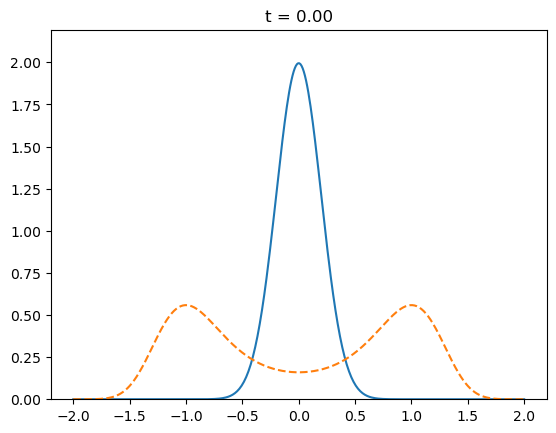

In [19]:
#The idea is to use the finite differance method to solve the fokker planck equation


import numpy as np

from scipy.ndimage import gaussian_filter1d

import matplotlib.pyplot as plt

from matplotlib.animation import FuncAnimation, PillowWriter


# These 2 are just very smart ways to compute the derivative and second degree derivative 
def first_derivative(x_array, h):
    dx_array = np.zeros(len(x_array))
    dx_array[1:-1] = (x_array[2:] - x_array[:-2]) / (2*h)
    return dx_array

def second_derivative(x_array, h):
    ddx_array = np.zeros(len(x_array))
    ddx_array[1:-1] = (x_array[2:] - 2*x_array[1:-1] + x_array[:-2]) / h**2
    return ddx_array

#This is the negative gradient of out potential function
def generate_double_well_gradient(x_array,a,b):
    return a*x_array - b*x_array**3

#The following function is to have reasonable starting conditions(MADE BY AI).
#Since we take the first and second derivatives, we want them to be reasonable.
#Hence, we use the gaussian_filter1d from scipy to smooth it out.

def initial_probability(n, corr_length, h):
    noise = np.random.randn(n)                                 # plain random noise
    smooth = gaussian_filter1d(noise, corr_length)             # blur it
    #smooth = smooth - np.linspace(smooth[0], smooth[-1], n)    # make the ends exactly 0 without creating jumps
    P = smooth ** 2                                            # no negative values
    P = P / (np.sum(P) * h)                                    # total probability = 1
    return P


#dP/dt = -d/dx[f(x)P]+ alpha * d^2P/dx^2
def dpdt_array_generator(P_array, fx_array,alpha,h):
    # Lets start by solving -d/dx[f(x)P]
    # First we have to multiply f(x) and P
    # Then we just have to take its gradient
    fx_times_P = fx_array * P_array
    derivative_fx_times_P = first_derivative(fx_times_P,h)
    #Now the diffusion term alpha * d^2P/dx^2
    second_derivative_P = second_derivative(P_array,h)
    diffusion_term_array = alpha * second_derivative_P
    # Now we combine these 
    dpdt_array = -1 * derivative_fx_times_P + diffusion_term_array
    return dpdt_array



# Lets start by generating the x axis
x_start = -2
x_end = 2
n_points = 400 #number of points
x_array = np.linspace(x_start, x_end, n_points)

# Lets then generate the starting P
h = x_array[1] - x_array[0]
# P_array = initial_probability(n = len(x_array), corr_length = 5, h = h)
x0 = 0
sigma = 0.2
P_array = np.exp(-(x_array - x0)**2 / (2*sigma**2))
P_array = P_array / (np.sum(P_array) * h)

# Now we generate the negative gradient of our potential function
a = 1
b = 1
fx_array = generate_double_well_gradient(x_array,a,b)

#Calculating #dP/dt = -d/dx[f(x)P]+ alpha * d^2P/dx^2
alpha = 0.2
dt = 0.4 * h**2 / alpha
t_end = 20
n_steps = int(t_end / dt)

#Saving graphs
n_saves = 100
save_every = n_steps // n_saves
P_history = [P_array]
t_history = [0]

for step in range(n_steps):
    dpdt_array = dpdt_array_generator(P_array = P_array , fx_array = fx_array , alpha = alpha, h = h)
    #Calculating the new P_array
    P_new = P_array + dpdt_array * dt
    P_array = P_new

    if (step + 1) % save_every == 0:
        P_history.append(P_array)
        t_history.append((step + 1) * dt)



fig, ax = plt.subplots()
line, = ax.plot(x_array, P_history[0])
V = -a*x_array**2/2 + b*x_array**4/4
P_exact = np.exp(-V/alpha)
P_exact = P_exact / (np.sum(P_exact) * h)
ax.plot(x_array, P_exact, "--")
ax.set_ylim(0, 1.1 * np.max(P_history))

def update(i):
    line.set_ydata(P_history[i])
    ax.set_title(f"t = {t_history[i]:.2f}")

anim = FuncAnimation(fig, update, frames=len(P_history), interval=50)
anim.save("fokker_planck.gif", writer=PillowWriter(fps=20))